# Classical Statistical Inference


## Table of Content

- I. Basic probability concepts
    * I.1 Probability axioms (see [Basic-statistics_01_Expanded.ipynb](Basic-statistics_01_Expanded.ipynb))
    * I.2 [What is a random variable ?](#I.2-What-is-a-random-variable-?)
    * I.3 [What is a conditional probability $p(A|B)p(A | B)$ and Bayes theorem ?](#I.3-What-is-a-conditional-probability-$p(A-|-B)$-and-Bayes-theorem?)
    * I.4 [Probability density function (PDF) and Cumulative Distribution Function (CDF)](#pdf)
        * `loc` and `scale` in `scipy.stats`
        * Density is *not* a probability (exercise)
        * I.4a [Common probability distributions](#I.4a-Common-Probability-distributions)
        * I.4b [Bivariate PDF](#bivariate)
        * I.4c [Multivariate Normal distribution](#I.4c-Multivariate-normal-distribution)
          
- To review the **properties of probability distribution functions** (mean, standard deviation, variance, skewness, ...), go to the notebook [Descriptive_statistics_01.ipynb](Descriptive_statistics_01.ipynb).    
- To do an interactive tour of the characteristics and properties of **common distributions** encountered in science, you can run the Notebook [Descriptive_statistics_02.ipynb](Descriptive_statistics_02.ipynb). 

- X. [References and supplementary material](#X)


In [1]:
# Modules to be used in this notebook
import numpy as np
import scipy.stats
import matplotlib.pyplot as plt
from matplotlib import gridspec
%matplotlib inline

# Our random number generator. The seed (10) is fixed so that everybody gets the same numbers.
# Change the seed (or call np.random.default_rng() without argument) to see the impact.
rng = np.random.default_rng(10)

## 0. Why some statistics?

Short answer: because randomness is there as soon as there are observational measurements (in all science fields, not only in astrophysics).

With this lecture, we aim to give you tools to manipulate data (from observations or from simulations). Data, even when being the outcome of some deterministic process, contain a stochastic component, for example due to the observational device. This means that, in essence, each data point is a *realisation* of what statisticians call a **random variable**. This is why, when you report measurements, you also need to report some uncertainties. These uncertainty calculations often look to students like some kind of black magic. This also means that they are sometimes not adequately used or reported. We will clarify in the coming lectures how to make those calculations using python tools.

This is a necessary step to enter into the field of machine learning. If you look on Wikipedia at the page dedicated to [Machine learning](https://en.wikipedia.org/wiki/Machine_learning), you will find the following definition: "Machine learning is the study of computer algorithms that improve automatically through experience. Machine learning algorithms build a mathematical model based on sample data, known as "training data", in order to make predictions or decisions without being explicitly programmed to do so." This is not the result of black magic, but of well understood statistics and probability.

In summary, data in science often contain randomness due to measurement errors or intrinsic variability. Understanding randomness is key to:

- Quantifying uncertainty
- Making predictions
- Building models (e.g., in machine learning)

## I Basic Probability Concepts and Notations  <a class="anchor" id="I"></a>

This section aims at reminding us of some definitions and notations, so everybody is on the same page. Illustrations with python are also provided.

In probability theory, we define the following:

- **Sample space ($\Omega$)**: the set of all possible outcomes of an experiment.
- **Realisation ($\omega$)**: an element (a point) of $\Omega$, i.e. one possible outcome. Each of your *data points* is a realisation, but there exist other possible realisations that are not in your data.
- **Event ($A$)**: a *subset* of $\Omega$ (a set of outcomes), $A \subset \Omega$. An event is defined by a condition on the outcomes, e.g. "the magnitude is between 15 and 15.5". Note that a *data set* (a sample) is **not** an event: it is a finite collection of realisations. One can however count how many of the data points fall in a given event.
- **Probability of an event $A$**: $p(A)$, a number between 0 and 1.
- **Random variable ($X$)**: a variable whose value is subject to randomness (formally, a function $X(\omega)$ that associates a number to each outcome).

> The *frequentist (classical) interpretation of probability*: you make a measurement, you repeat it a (very large, in the limit infinite) number of times, and build a histogram. This histogram gives the *relative frequency* of getting a measurement compared to another. This relative frequency is what we call a probability.

**Example**: We measure the magnitude $m$ of a variable star. Then $\Omega = \mathbb{R}$ (or some plausible range such as $]-30, 40[$, but this makes little difference in practice and $\Omega$ can in general be larger than needed). $\omega$ is a value in $\Omega$, while an event is e.g. "the measured magnitude satisfies $15 < m \leq 15.5$", hence this *event* is $A = \,]15, 15.5]$. Note that an event *can* also be a single point (i.e. $A = \{17\}$).

If you need some refresh on basic probability concepts, move to the expanded version of this notebook (`Basic-statistics_01_Expanded.ipynb`).

### I.1 Probability axioms

Check the [expanded version of this notebook](Basic-statistics_01_Expanded.ipynb) to refresh your mind about the axioms behind the probability theory.

### I.2 What is a random variable and how to generate them in Python? 

Definition (informal):

> A random variable is a variable whose value results from the measurement of a quantity that is subject to random variations.

**Example:**

**Discrete random variable**: You roll a die 10 times and record the sequence of outcomes, e.g. $\omega = (1, {\bf 2, 4, 2}, 5, {\bf 4, 6}, 3, 3, 1)$ (an *ordered* sequence, hence round brackets: the sample space is $\Omega = \{1,\dots,6\}^{10}$). You can then define $X(\omega)$ to be the *number of times you drew an even number* in the sequence $\omega$. Here, the even outcomes are ${\bf 2, 4, 2, 4, 6}$, so $X(\omega) = 5$ is the value taken by your *random variable* $X$.

**Continuous random variable**: You measure the velocity of a star by means of its apparent motion on the sky. The apparent motion (in arcsec), but also the inferred velocity (that involves feeding in the distance to the star) will take continuous values.

**Warning**: a random variable is *NOT* like a typical mathematical variable, as it can take *different values* (each with an associated probability). In the literature, you will generally find random variables written with *CAPITAL* letters, and their particular *realisation* with *lowercase* letters. A realisation of a random variable is also called a "random variate".

**Random variables with numpy**

In numpy there is a sub-module called `random` that contains many functions that involve random selection. The recommended way to use it is to create **once** a *random number generator* object, and then to call the methods of this object:

```python
rng = np.random.default_rng(10)   # 10 is the seed; see the first cell of this notebook
```

The generator `rng` has an internal state, that evolves each time you ask for a random number. Two consequences:

- two successive calls give different numbers (the generator "moves on" in its stream of numbers);
- the same seed always generates the same stream: this makes your results *reproducible*. Re-running a cell that uses `rng` does not give the same numbers again, because `rng` is not re-initialised: to restart from scratch, re-run the cell where `rng` is created.

An important method associated to this random generator is `choice`, which makes a choice at random. It picks one item at random from an array, and it is equally likely to pick any of the items. The function call is `rng.choice(array_name)`, where `array_name` is the name of the array from which to make the choice.

In [2]:
# Let's build a small array with classification of objects on an image:
class_phot = np.array(['star', 'galaxy', 'galaxy', 'star', 'star'])
rng.choice(class_phot)

np.str_('star')

If you re-run the above cell multiple times, you will see that the output changes, because the output is taken at random. If you provide a second argument (`size = n`), it will repeat the process $n$ times. In practice, this method allows you to *generate a random sample* from a 1-D array. You can add a third argument that specifies if you allow replacement or not: `replace=False` means that a given element of the array can only be drawn once.

In [3]:
rng.choice(class_phot, size=3)

array(['star', 'galaxy', 'galaxy'], dtype='<U6')

In [5]:
# Use e.g. np.arange(5) and size=5 to compare the behaviour with replace=True / replace=False
# replace = True
my_array_of_values = 
rng.choice(my_array_of_values, size=, replace=)

array([3, 4, 2, 0, 4])

In [6]:
# replace = False
rng.choice(my_array_of_values, size=, replace=)

array([4, 0, 2, 1, 3])

In [7]:
# Try out with a sample size (6) larger than the array size (5)
# replace = False  -> this is not possible, and python tells you so:
try:
    rng.choice(my_array_of_values, size=6, replace=False)
except ValueError as err:
    print('ValueError:', err)

ValueError: Cannot take a larger sample than population when replace is False


In [8]:
# replace = True  -> no problem
rng.choice(my_array_of_values, size=6, replace=True)

array([2, 2, 4, 1, 4, 0])

If `size` > the number of elements of the array, you cannot generate a random sample with `choice` and `replace=False` (it does not make sense: you cannot draw more distinct elements than the array contains).

Other important methods of the generator `rng` are:

- `rng.random(n)`: generate an array of $n$ random floats drawn from a uniform distribution on $[0, 1)$.
- `rng.integers(low, high, size)`: generate an array of random integers between `low` (included) and `high` (**excluded**).
- `rng.permutation(array_name)`: return a copy of the original array with elements permuted (along the first axis).
- `rng.normal(loc, scale, size)`, `rng.standard_normal(size)`, `rng.poisson(lam, size)`, ...: draw directly from common distributions (we will rather use `scipy.stats` below).

**Note: the `np.random.xxx` functions called "on the fly" (legacy interface)**

You will see in many tutorials and older codes calls such as `np.random.seed(10)`, `np.random.rand(3)`, `np.random.randint(0, 2, size=1000)`, `np.random.choice(...)`. This is also valid and still works. These functions all use *one hidden, global* generator (a `RandomState` object using the Mersenne-Twister algorithm). It is simple for a quick test, but it is easy to get confused with the seed: `np.random.seed` acts on a global state that every piece of code (including the libraries you import) can modify, and it has no effect on a generator you created with `default_rng`. The explicit object `rng = np.random.default_rng(seed)` is easier to follow: you see where the random numbers come from, you can have several independent generators, and you can pass `rng` to functions. It is also what the numpy documentation recommends for new code. The correspondence between the two interfaces is:

| legacy (global) | with a generator `rng` |
|---|---|
| `np.random.seed(10)` | `rng = np.random.default_rng(10)` |
| `np.random.rand(n)` | `rng.random(n)` |
| `np.random.randint(low, high, size)` | `rng.integers(low, high, size)` |
| `np.random.choice(a, ...)` | `rng.choice(a, ...)` |
| `np.random.permutation(a)` | `rng.permutation(a)` |
| `np.random.randn(n)` / `np.random.normal(...)` | `rng.standard_normal(n)` / `rng.normal(...)` |
| `np.random.RandomState(10)` | `np.random.default_rng(10)` |

Note that the same seed does **not** give the same numbers with the two interfaces, because they use different algorithms (Mersenne-Twister for the legacy interface, PCG64 for `default_rng`). Depending on your problem, you may want to dig more into the specificities of the available random number generators (see the numpy documentation and [https://www.pcg-random.org/](https://www.pcg-random.org/)). A specific algorithm can be chosen with e.g. `from numpy.random import Generator, PCG64; rng = Generator(PCG64(10))`.

#### Exercise: Coin toss

- (1) Create a 1-D array representing the result of 1000 coin tosses (set value `0` for head and `1` for tail, using the random integer generator `rng.integers`). Plot the histogram of their values (using `matplotlib.pyplot.hist`; note that you can set the number of bins $N$ with the argument `bins = N`). Set the argument `density` of `hist()` to the values `True` and `False`. What is the difference of behaviour?
- (2) Create an array `a` of 10 integers between 0 and 9 with your generator. Redo this operation and save it into an array `b`. Compare `a` and `b`. How should you proceed to have 2 identical arrays?

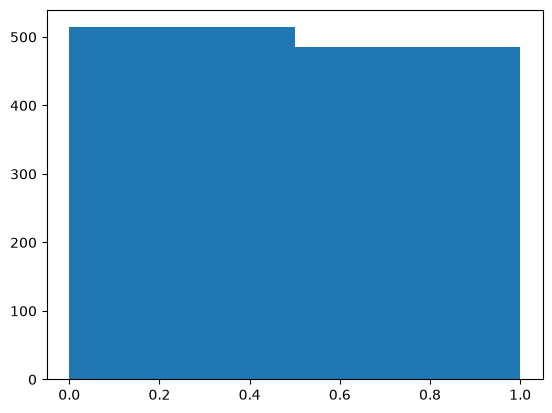

In [9]:
# (1) 1D array representing 1000 coin tosses and histogram.
coin_tosses = rng.integers()   # 0 = head, 1 = tail (upper bound 2 is excluded)
hist_vals = plt.hist(coin_tosses, bins=2)

In [10]:
hist_vals

(array([514., 486.]),
 array([0. , 0.5, 1. ]),
 <BarContainer object of 2 artists>)

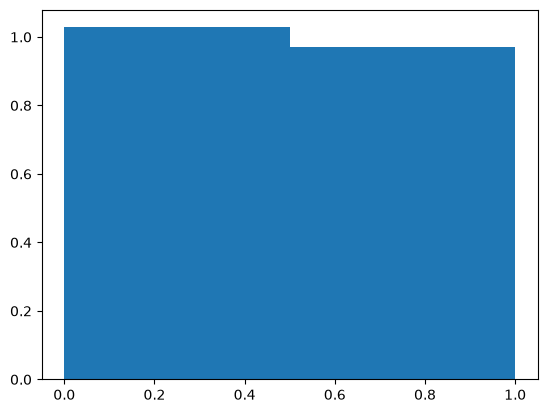

In [11]:
# If you want to get a normalised histogram
hist_vals = plt.hist(coin_tosses, bins=2, density=True)

Text(0, 0.5, 'Number of occurrences')

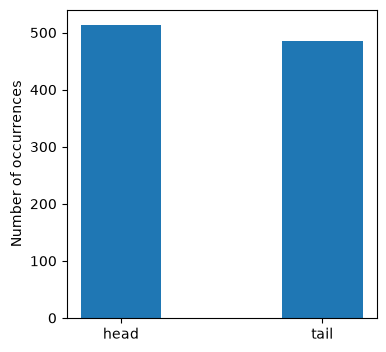

In [12]:
# To make a slightly nicer histogram
f, ax = plt.subplots(figsize=(4, 4))
hist_vals = ax.hist(coin_tosses, bins=2, align='mid', rwidth=0.4)   # see the help of hist for details
ax.set_xticks([0.25, 0.75])
ax.set_xticklabels(['head', 'tail'])
ax.set_ylabel('Number of occurrences')

In [13]:
# (2) Two arrays of 10 integers between 0 and 9, drawn one after the other from the SAME generator
a = rng.integers()
b = rng.integers()
a, b

(array([0, 4, 7, 9, 2, 7, 0, 2, 1, 1]), array([9, 9, 2, 4, 4, 4, 6, 3, 0, 3]))

`a` and `b` are different: the generator `rng` continues its stream of numbers where it stopped. To obtain two identical arrays, we need to start from the same state, i.e. to create two generators with the same seed (or to re-create the generator before each draw):

In [14]:
rng_a = np.random.default_rng(10)
a = rng_a.integers(0, 10, size=10)
rng_b = np.random.default_rng(10)
b = rng_b.integers(0, 10, size=10)
print(a)
print(b)
print('Identical arrays ?', np.array_equal(a, b))

[7 9 2 2 7 8 5 1 8 5]
[7 9 2 2 7 8 5 1 8 5]
Identical arrays ? True


**Remark: what about the legacy command  `np.random.seed`?** With the global interface, you would write `np.random.seed(10)` before *each* draw you want to reproduce. It works, but the seed acts on a hidden global state, and it has no influence on `rng`:

In [16]:
# The legacy global seed does not influence generators created with default_rng
r1 = np.random.default_rng(10)
np.random.seed(0)                 # some global seed ...
u = r1.random(3)
r2 = np.random.default_rng(10)
np.random.seed(999)               # ... another global seed
v = r2.random(3)
print('np.random.seed() does NOT change default_rng seed')
print('Same numbers?', np.array_equal(u, v))

np.random.seed() does NOT change default_rng seed
Same numbers? True


In [17]:
# Legacy interface: same seed => same numbers, but NOT the same numbers as default_rng(10)
np.random.seed(10)
legacy = np.random.randint(0, 10, size=10)
print('legacy     :', legacy)
print('default_rng:', np.random.default_rng(10).integers(0, 10, size=10))

legacy     : [9 4 0 1 9 0 1 8 9 0]
default_rng: [7 9 2 2 7 8 5 1 8 5]


### I.3 What is a conditional probability $p(A\,|\,B)$ and Bayes' theorem?

The conditional probability expresses the fact that the probability of an event can depend on another one. For example, you may wonder what is the probability to have the flu if you have a fever. You would write it $p(\rm{flu}\,|\,\rm{fever})$, which reads "p of flu GIVEN fever". Its definition is $p(A \, | \, B) = \frac{p(A \, \cap \, B)}{p(B)}$ (for $p(B) > 0$): it is the *fraction of the cases where $B$ occurs in which $A$ occurs as well*. Think of the sample space restricted to the cases where $B$ is true, and $A\,|\,B$ is the proportion of those cases in which $A$ is also true.

Bayes' theorem expresses formally how to turn one conditional probability into the reverse one:

$$
p(A\,|\,B) = \frac{p(B\,|\,A) \, p(A)}{p(B)}
$$

The main thing you have to recall with conditional probability is that $p(A\,|\,B) \neq p(B\,|\,A)$ in general: the probability of having the flu given that you have a fever is different from the probability of having a fever given that you have the flu.

### I.4 Probability density function (PDF) and Cumulative Distribution Function (CDF)

These concepts are essential for:

- Predicting probabilities of events.
- Modeling uncertainties in measurements.
- Designing experiments and interpreting data.

#### Probability density function - PDF

For a continuous random variable, the PDF $h(x)$ describes the *relative likelihood* of the values of $X$. It is **not** itself a probability (see the section "Density is not a probability" below): since we are dealing with probability *densities*, $h(x)\,{\rm d}x$ is the probability of a value falling between $x$ and $x + {\rm d}x$, and for an interval $[x_1, x_2]$:

$$
p(x_1 \leq X \leq x_2) = \int_{x_1}^{x_2} h(x)\,{\rm d}x
$$

Probability densities are normalised such that the union of all possible events has a probability of unity; mathematically that criterion looks like this:

$$
\int_{-\infty}^{+\infty} h(x)\,{\rm d}x = 1
$$

Remember the histogram counting your measurements (cf. the exercise on [coin toss](#exercise-coin-toss) above), with `density=True`. The heights $h_i$ of the bins are then such that $\sum_i h_i \, \delta x_i = 1$ (where $\delta x_i$ is the bin width). The histogram is thus an *estimate of the probability density* from a finite sample. (For a discrete variable, the analogue of a density is the probability mass function, see below.)

If the concept of PDF was not already clear to you, check Section I.4 of the [expanded version](Basic-statistics_01_Expanded.ipynb) of this notebook for the more formal definition of the pdf.

**Examples:** you know several pdfs, such as the *uniform* and the *normal* (aka gaussian) pdf.

- A *uniform* pdf on $[a, b]$ is such that:

$$
\begin{array}{lll}
   h(x)    & = \dfrac{1}{b-a} & {\rm if}\;\, a\,\leq\,x\,\leq\,b \\[2mm]
   h(x)    & = 0 & {\rm otherwise}
\end{array}
$$

- The gaussian pdf of mean $\mu$ and standard deviation $\sigma$ is:

$$
h(x \,|\, \mu, \sigma) = \frac{1}{\sqrt{2\pi}\,\sigma} \exp \left( -\frac{1}{2}\frac{(x-\mu)^2}{\sigma^2}\right)
$$

It is important to keep in mind that the *integral* of $h(x)$ over its domain has to be 1, otherwise we do not have a properly normalised pdf. This explains the normalisation factor $1/(\sqrt{2\pi}\,\sigma)$ in front of the gaussian pdf. Note that this does **not** mean that $h(x) \leq 1$: for the uniform pdf with $b - a = 0.1$ we have $h(x) = 10$ on $[a,b]$, and a gaussian with $\sigma < 1/\sqrt{2\pi} \approx 0.4$ has a maximum larger than 1. Only probabilities (areas under the pdf) are bounded by 1.

- In cases where random variables are **discrete**, one rather speaks of **probability mass function** (pmf). In this case, $X$ may take a (finite or countable) number of values $\{x_1, x_2, \dots\}$ and the mass function is simply:

$$
h_X(x_i) = p(X = x_i), \qquad \sum_i h_X(x_i) = 1
$$

Here the values of the pmf *are* probabilities (so they are between 0 and 1). The *Poisson* and *Bernoulli* distributions are examples of pmf.

#### Cumulative distribution function - CDF

The CDF gives the probability that the variable is less than or equal to a value.

The **cumulative distribution function** is the *integral of a pdf*:

$$
p(X \leq x) = H(x) = \int_{-\infty}^{x}\, h(x') \, {\rm d}x'
$$

By definition, $H$ increases from $H(-\infty) = 0$ to $H(+\infty) = 1$ (this is the normalisation of the pdf).

The CDF provides a direct way to calculate the probability for the value of a random variable $X$ to be between 2 values $x_1$ and $x_2$. If $x_1 < x_2$, then $p(x_1 < X \leq x_2) = H(x_2) - H(x_1)$.

The *$p$% quantile* of a distribution, $q_p$, is defined as:

$$
\frac{p}{100} = \int_{-\infty}^{q_p} h(x)\, {\rm d}x \quad (\text{i.e. } H(q_p) = p/100)
$$

$q_{25}$, $q_{50}$ and $q_{75}$ are commonly called the first, second and third *quartile* (or 25 / 50 / 75 *percentile*) of the distribution. $q_{75} - q_{25}$ is called the *interquartile range* and provides a robust estimate of the width of a distribution. By definition, the area under the PDF between $q_{25}$ and $q_{75}$ is 0.5, i.e. the *interquartile range* contains 50% of the probability (around the median for a symmetric distribution). We will see later how to use percentiles to calculate confidence intervals.

#### Quantities describing a distribution

The (raw) moment of order $k$ of a distribution is defined as:

$$
\mathbb{E}(X^k) = \, \int_{-\infty}^{+\infty} x^k\,h(x)\,{\rm d}x
$$

The **mean** (also called *expectation value* or *expected value*) is the moment of order 1 (a *raw* moment, i.e. not centred). This is related to the frequentist interpretation of an experiment: if you repeat an experiment an infinite number of times, this will be the average value that you get. Intuitively, the mean is *the sum of all the outcomes weighted by their probability of occurrence*:

$$
\mathbb{E}(X) \, = \langle X \rangle \, = \, \int_{-\infty}^{+\infty} x\,h(x)\,{\rm d}x
$$

For example, by feeding the expression of the uniform pdf above, you can easily verify that its mean is $(a+b) / 2$.

The *central* moments are the moments **around the mean**, $\mathbb{E}[(X - \mathbb{E}(X))^k]$ (the central moment of order 1 is therefore always 0). The **variance** is the central moment of order 2 and tells you about the spread around the mean:

$$
{\rm{Var}}(X) = \mathbb{E}\left[ (X - \mathbb{E}(X))^2\right] =  \mathbb{E}(X^2) - \mathbb{E}(X)^2 = \, \int_{-\infty}^{+\infty} (x-\langle X \rangle)^2\,h(x)\,{\rm d}x
$$

The standard deviation is $\sigma = \sqrt{{\rm Var}(X)}$. For a uniform distribution, you may derive that ${\rm{Var}}(X) = (b-a)^2 / 12$.

#### pdf and CDF in python

A large number of distribution functions are implemented in `scipy.stats`, such as the binomial distribution, Poisson distribution, gaussian distribution, chi2, Cauchy distribution, ... To use them you simply have to:

**Method 1**

You work in two steps. It allows you to calculate multiple quantities associated to a distribution.

- 1) **Create an instance of an object "distribution"** with some fixed parameters, e.g.:

```python
# Create a gaussian function with parameters mu=0, sigma=2
g = scipy.stats.norm(0, 2)

# Poisson distribution for 10 events
pois = scipy.stats.poisson(10)
```

**Note:** The help of `scipy.stats` distributions refers to the `loc` and `scale` keywords. For the gaussian `norm`, `loc` happens to be the mean and `scale` the standard deviation, **but this is not true in general**: see the section "`loc` and `scale`" below.

In [5]:
g = scipy.stats.norm(0, 2)
# More explicit call: g = scipy.stats.norm(loc=0, scale=2.)

- 2) Calculate **properties associated to (the instance of) this object** using a set of *specific methods*. For the pdf, use the method `pdf`:

```python
# Evaluate the pdf / pmf associated to our objects g / pois at "position" x / k

g_pdf = g.pdf(x)        # x is either a numpy array or a specific value

pois_pmf = pois.pmf(k)  # k is an array of integers or a specific value
```

**Method 2**

You can generate a `pdf` associated to a normal distribution with a single command line:

```python
x = np.arange(-10, 10, 0.1)   # Create an array over which you want to evaluate the pdf

y = scipy.stats.norm.pdf(x, loc=0, scale=2)   # for a gaussian of mean mu=0, sigma=2
```

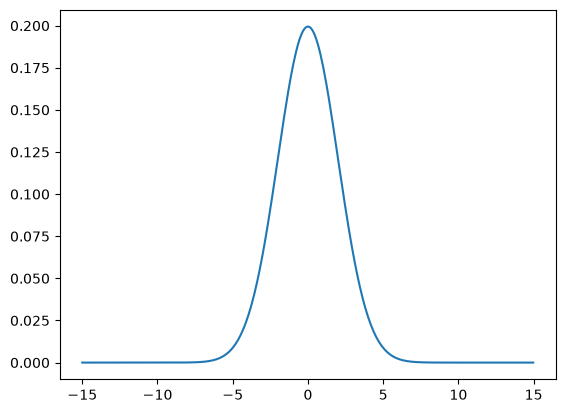

In [6]:
# Use this cell to plot the pdf associated with the gaussian distribution you have generated above
x = np.arange(-15, 15, 0.09)
g_pdf = g.pdf(x)
plt.plot(x, g_pdf)

Integral when step = 0.01 = 1.000 - But sum = 99.994
Integral when step = 0.10 = 1.000 - But sum = 9.999


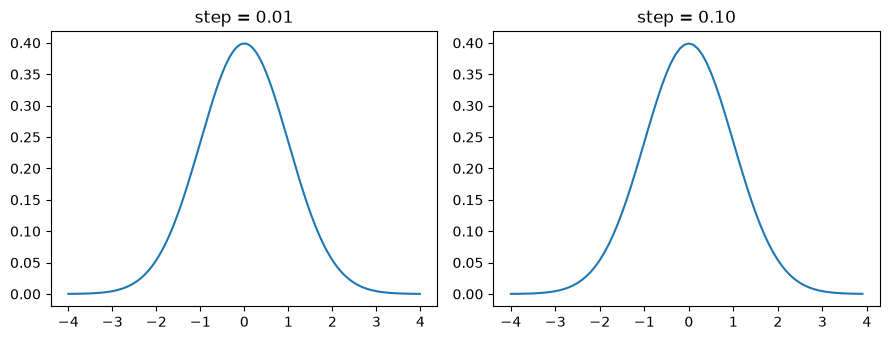

In [7]:
# The y axis does not depend on the way you sample your pdf but the sum does
f, ax = plt.subplots(ncols=2, figsize=(9, 3.5))
for i, step in enumerate([0.01, 0.1]):
    n1d = scipy.stats.norm(0, 1)
    x = np.arange(-4, 4, step)
    n1d_pdf = n1d.pdf(x)
    print('Integral when step = %.2f = %.3f - But sum = %.3f' % (step, np.sum(n1d_pdf * step), np.sum(n1d_pdf)))
    ax[i].plot(x, n1d_pdf)
    ax[i].set_title('step = %.2f' % step)
plt.tight_layout()

#### An example of PMF: the Poisson distribution

Now, let's have a look at a Poisson distribution (probability mass function). Hereafter, we use $k$ to denote the discrete random variable.

$$
\rm{Pois}(k\,|\,\mu) = \frac{\mu^k e^{-\mu}}{k!}
$$

**Parameter:** $\mu$ - the expected number of (random) events

Expectation: $\mu$

Standard deviation: $\sqrt{\mu}$

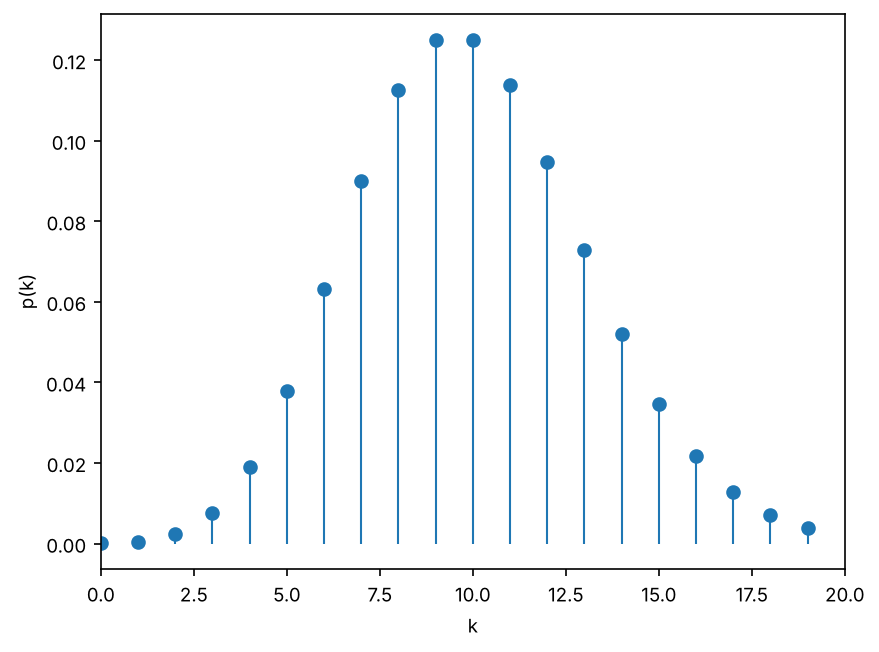

In [21]:
# Let's now do it for a probability mass function
x = np.arange(0, 20, 1)       # integers: the Poisson variable is discrete
mu = 10
pois = scipy.stats.poisson(mu)
pois_pmf = pois.pmf(x)
plt.plot(x, pois_pmf, 'o', label='pmf')            # a pmf only exists at integer values:
plt.vlines(x, 0, pois_pmf, color='C0', lw=1)        # we draw points/sticks rather than a continuous line
plt.xlim(0, 20)
plt.xlabel('k'); plt.ylabel('p(k)')

#### Random samples from a distribution

Other properties of the object (mean, std, moments, ...) can be calculated as we will see later. It is also possible to draw a random sample that follows the distribution we want to use, using the method `rvs()` (random variates). To use the generator `rng` (so that the sample is reproducible and consistent with the rest of the notebook), pass it with the argument `random_state`:

```python
# Generate a sample of 1000 points drawn from a gaussian distribution:
g_sample = g.rvs(size=1000, random_state=rng)

# Generate a sample of 10 points drawn from a Poisson distribution:
pois_sample = pois.rvs(size=10, random_state=rng)
```

(If you do not provide `random_state`, scipy uses the legacy global generator of numpy, i.e. `np.random.seed` would act on it.)

See Sect. 3.2 of our reference [book](#book) for an overview of the main distributions implemented in scipy.

In [ ]:
sample_from_poisson =
sample_from_poisson

In [ ]:
plt.hist(sample_from_poisson, density=True)
plt.plot(x, pois_pmf)
plt.xlim(0, 20)

#### Visualising the CDF

In the case of a gaussian PDF, the CDF $H(x_0) = p(X \leq x_0)$ is the area below the PDF between $-\infty$ and $x_0$.

The CDF provides a direct way to calculate the probability for the value of a random variable $X$ to be between 2 values $x_1$ and $x_2$. If $x_1 < x_2$, then $p(x_1 < X \leq x_2) = H(x_2) - H(x_1)$. On the figure below, this would be the difference of the area up to $x_2$ minus the area up to $x_1$.

(-4.0, 4.0)

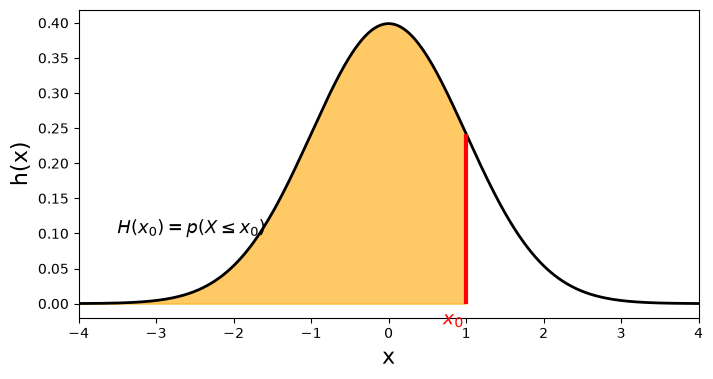

In [10]:
x = np.arange(-6, 6, 0.01)
x0 = 1.   # let's take x0 = 1
id_x0 = np.searchsorted(x, x0)
g = scipy.stats.norm(loc=0, scale=1)
f, ax = plt.subplots(ncols=1, figsize=(8, 4))

ax.plot(x, g.pdf(x), color='black', lw=2)

ax.vlines(x0, 0, g.pdf(x0), color='red', lw=3)
ax.fill_between(x[:id_x0], 0, g.pdf(x[:id_x0]), color='orange', alpha=0.6)
ax.set_ylabel('h(x)', size=16)
ax.set_xlabel('x', size=16)
ax.text(x0 - 0.3, -0.03, r'$x_0$', size=14, color='red')
ax.text(-3.5, 0.1, r'$H(x_0) = p(X \leq x_0)$', size=13)
ax.set_xlim(-4, 4)

H(1) = p(X <= 1) = 0.841


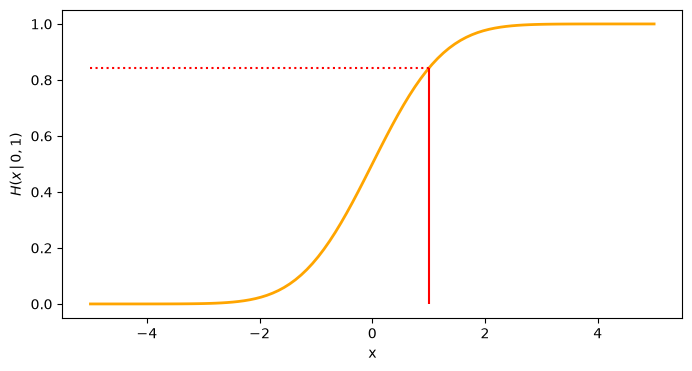

In [11]:
# CDF of a gaussian
f, ax = plt.subplots(ncols=1, figsize=(8, 4))
n = scipy.stats.norm(0, 1)
x = np.linspace(-5, 5, 100)

g_cdf = n.cdf(x)

ax.plot(x, g_cdf, lw=2, color="orange")
ax.vlines(1, 0, n.cdf(1), color='red')                  # H(1) = 0.841
ax.hlines(n.cdf(1), -5, 1, color='red', ls=':')
ax.set_ylabel("$H(x\\,|\\,0, 1)$")
ax.set_xlabel("x")
print('H(1) = p(X <= 1) = %.3f' % n.cdf(1))

**Exercises:**

- Generate a random sample of $n$ points drawn from the gaussian distribution you defined above (compare $n$ = 10, 100, 1000).
- Plot a histogram with the sample of points you have generated.
- Plot a canonical gaussian pdf (width = 1) and overplot a horizontal line showing its FWHM.
- Print on the screen the value of the FWHM and compare with the value you expect for a canonical 1D-gaussian (FWHM $= 2 \sqrt{2 \ln 2}\,\sigma$).

TIP: Keep the expression of the FWHM of a gaussian in mind, you may have to use it often.

In [ ]:
# Use this cell to generate a random sample of points drawn from the gaussian distribution you defined above
# let's take a canonical gaussian N(0,1)
g_canon = 

In [ ]:
# plotting the histogram
f, ax = plt.subplots(ncols=3, figsize=(10, 5))
for i, npts in enumerate([10, 100, 1000]):
    random_samples = -st
    ax[i].hist(random_samples)
    ax[i].set_title('n points = %i'%npts)

In [ ]:
# Illustration of a canonical gaussian pdf and overplot of a line showing its FWHM
x = np.arange(-10,10,0.01)
g_samp_10000 =
plt.hist(g_samp_10000, density = True, bins=100)
#plt.hist(g_samp_10000, bins=100)
plt.plot(x, g_canon.pdf(x))
# Overlay the fwhm
sig_canon = 1
fwhm_vmin = 0 -
fwhm_vmax = 0 +
plt.hlines(g_canon.pdf(x).max()/2, fwhm_vmin, fwhm_vmax, color='red')

In [ ]:
sig_draw = np.std(g_samp_10000)
print('Empirical FWHM: %.3f' %( 2. * np.sqrt( 2. * np.log(2.)) * sig_draw) )
print('Canonical FWHM %.3f '%( 2. * np.sqrt( 2. * np.log(2.))) )

In [24]:
## !! BEWARE
print( 'Base 10 log of 2 = %.2f ' %np.log10(2), 'but natural log of 2, i.e. ln(2)=%.2f '%np.log(2.))

Base 10 log of 2 = 0.30  but natural log of 2, i.e. ln(2)=0.69 


You can also calculate various statistics associated to your distribution such as the mean, median, standard deviation, moments, ...

In [25]:
# Let's take a canonical normal distribution with (mu, sigma) = (0,1)
n = scipy.stats.norm(0, 1)
print('Mean = %.2f  ' %n.mean() )
print('Median = %.2f  ' %n.median() )
print('Stdev = %.2f  ' %n.std() )
print('Moment of order 4, E[x^4] = %.2f' %n.moment(4) )

# CAUTION: in scipy, moment(k) is the RAW moment E[x^k], not the central one.
# It coincides with the central moment only when the mean is 0. Take a gaussian of mean 2:
n2 = scipy.stats.norm(2, 1)
print()
print('N(2,1): E[x]   = %.2f' % n2.moment(1))
print('N(2,1): E[x^2] = %.2f  (= sigma^2 + mu^2, NOT the variance)' % n2.moment(2))
print('N(2,1): Var    = %.2f  (the central moment of order 2)' % n2.var())

Mean = 0.00  
Median = 0.00  
Stdev = 1.00  
Moment of order 4, E[x^4] = 3.00

N(2,1): E[x]   = 2.00
N(2,1): E[x^2] = 5.00  (= sigma^2 + mu^2, NOT the variance)
N(2,1): Var    = 1.00  (the central moment of order 2)


You can also calculate the $p$ percentile of a distribution with the "percent point function" or `ppf` (i.e. the inverse of the cdf): `scipy.stats.distrib.ppf(q)`, where $q = p/100$ is between 0 and 1.

In [26]:
print('q_25 and q_75 are %.3f , %.3f' %(n.ppf(0.25), n.ppf(0.75)) )
print('The interquartile range is %.3f' % (n.ppf(0.75)- n.ppf(0.25)) )

q_25 and q_75 are -0.674 , 0.674
The interquartile range is 1.349


Let's visualise what the inter-quartile range is. *Look at the code and figure* to ensure that you understand the relation between `ppf`, `cdf` and `pdf`.

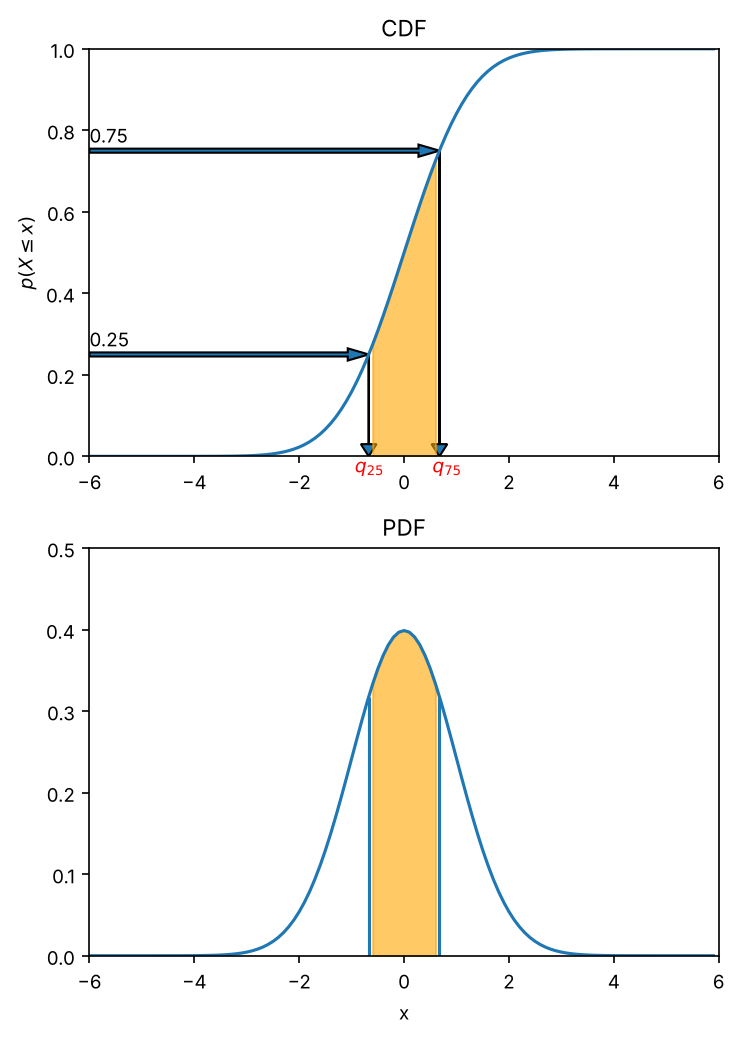

In [27]:
f, ax = plt.subplots(nrows=2, figsize=(5, 7))
x = np.arange(-6, 6, 0.1)
ax[0].set_title('CDF')
ax[0].plot(x, n.cdf(x))

# The ppf is the inverse of the CDF => it reads the function from the y axis
# Draws 2 arrows from y=0.25 and y=0.75.
# Definition of ax.arrow(): ax.arrow(x, y, dx, dy)
ax[0].arrow(-6, 0.25, n.ppf(0.25)+6, 0., width=0.01, length_includes_head=True, head_length=0.4)
ax[0].arrow(-6, 0.75, n.ppf(0.75)+6, 0., width=0.01, length_includes_head=True, head_length=0.4)
ax[0].text(-6, 0.27, '0.25')
ax[0].text(-6, 0.77, '0.75')

# The ppf returns the x for which cdf(x = q_{25}) = 0.25 and cdf(x = q_{75}) = 0.75
q25, q75 = n.ppf(0.25), n.ppf(0.75)
id25, id75 = np.searchsorted(x, q25), np.searchsorted(x, q75)
ax[0].arrow(n.ppf(0.25), 0.25, 0, -0.25, width=0.01, length_includes_head=True, head_width=0.3, head_length=0.03)
ax[0].arrow(n.ppf(0.75), 0.75, 0, -0.75, width=0.01, length_includes_head=True, head_width=0.3, head_length=0.03)
ax[0].text(0.54, -0.04, '$q_{75}$', color='red' )
ax[0].text(-0.94, -0.04, '$q_{25}$', color='red' )
ax[0].fill_between(x[id25:id75], n.cdf(x[id25:id75]), 0, color='orange', alpha=0.6)

ax[0].set_ylabel('$p(X \\leq x)$')

ax[1].plot(x, n.pdf(x))
ax[1].set_title('PDF')
ax[1].set_xlabel('x')

# Let's plot 2 vertical lines and colour the area corresponding to the interquartile range
ax[1].vlines(q25, 0, n.pdf(q25))
ax[1].vlines(q75, 0, n.pdf(q75))
ax[1].fill_between(x[id25:id75], n.pdf(x[id25:id75]), 0, color='orange', alpha=0.6)

qq = [ax[i].set_xlim(-6, 6) for i in range(2)]
ax[0].set_ylim(0, 1)
ax[1].set_ylim(0, 0.5)
plt.tight_layout()

The region delimited by the 2 vertical black lines on the bottom panel corresponds to the interquartile range. The orange area under the PDF is 50% of the total area, which means that 50% of the total probability is in that range. The $q_{25}, q_{50}, q_{75}$ quartiles divide the distribution into 4 parts of equal probability. There is a 25% probability for a value $X$ to be $X < q_{25}$, and a 25% probability for a value $X$ to be $X > q_{75}$.

#### About `loc` and `scale` in `scipy.stats`

The arguments `loc` and `scale` in `scipy.stats` can look a bit confusing. This is because the distributions are expressed in their standardised form. 

Every continuous distribution of `scipy.stats` is defined in a **standardised form**, and `loc` and `scale` are the two generic parameters that shift and stretch it. If $Z$ follows the standardised distribution (`loc=0`, `scale=1`), then the variable

$$
X = {\rm loc} + {\rm scale} \times Z
$$

follows the distribution `dist(loc=loc, scale=scale)`. Its pdf is obtained from the standardised one $h_Z$ by

$$
h_X(x) = \frac{1}{\rm scale}\; h_Z\!\left(\frac{x - {\rm loc}}{\rm scale}\right)
$$

where the factor $1/{\rm scale}$ is there to keep the pdf normalised (stretching the $x$ axis lowers the density). In words: `loc` *translates* the distribution along $x$, `scale` *stretches* it.

What `loc` and `scale` mean physically therefore depends on what the standardised distribution looks like:

| distribution | standardised form ($Z$) | meaning of `loc` | meaning of `scale` | mean | std |
|---|---|---|---|---|---|
| `norm` | $\mathcal{N}(0,1)$ | the mean $\mu$ | the std $\sigma$ | `loc` | `scale` |
| `uniform` | uniform on $[0,1]$ | lower bound $a$ | width $b-a$ (!) | `loc + scale/2` | `scale/`$\sqrt{12}$ |
| `expon` | $e^{-z}$ for $z\geq 0$ | starting point (threshold) | $1/\lambda$ (mean waiting time) | `loc + scale` | `scale` |

So `scipy.stats.uniform(loc=a, scale=b-a)` is the uniform pdf on $[a, b]$ of the previous section: `scale` is *not* $b$. Only for the gaussian `loc` and `scale` coincide with the mean and the standard deviation. Discrete distributions have a `loc` (a shift of the integer values $k$) but no `scale`; the parameters of e.g. `poisson(mu)` or `binom(n, p)` are given as separate arguments. Some distributions need additional *shape* parameters, which come before `loc` and `scale` (e.g. `scipy.stats.gamma(a, loc, scale)`).

In [8]:
# 1) Check numerically that dist(loc, scale) is the shifted and stretched standardised distribution
x = np.linspace(-2, 12, 1000)
loc, scale = 2.0, 3.0
for name, dist in [('norm', scipy.stats.norm), ('uniform', scipy.stats.uniform), ('expon', scipy.stats.expon)]:
    h_from_std = dist.pdf((x - loc) / scale) / scale          # (1/scale) h_Z((x-loc)/scale)
    h_scipy = dist(loc=loc, scale=scale).pdf(x)
    print('%-8s pdf relation satisfied: %s' % (name, np.allclose(h_from_std, h_scipy)))

# 2) Mean and std are NOT always (loc, scale)
print()
print('loc = %.1f, scale = %.1f' % (loc, scale))
for name, dist in [('norm', scipy.stats.norm), ('uniform', scipy.stats.uniform), ('expon', scipy.stats.expon)]:
    d = dist(loc=loc, scale=scale)
    print('%-8s mean = %5.2f   std = %5.2f' % (name, d.mean(), d.std()))

# 3) A sample generated by rvs is  loc + scale * (standardised sample)
z = scipy.stats.expon.rvs(size=100000, random_state=rng)
sample = loc + scale * z
print()
print('Mean/std of loc + scale * z : %.2f / %.2f  (expected %.2f / %.2f)'
      % (sample.mean(), sample.std(), scipy.stats.expon(loc, scale).mean(), scipy.stats.expon(loc, scale).std()))

norm     pdf relation satisfied: True
uniform  pdf relation satisfied: True
expon    pdf relation satisfied: True

loc = 2.0, scale = 3.0
norm     mean =  2.00   std =  3.00
uniform  mean =  3.50   std =  0.87
expon    mean =  5.00   std =  3.00

Mean/std of loc + scale * z : 5.00 / 3.00  (expected 5.00 / 3.00)


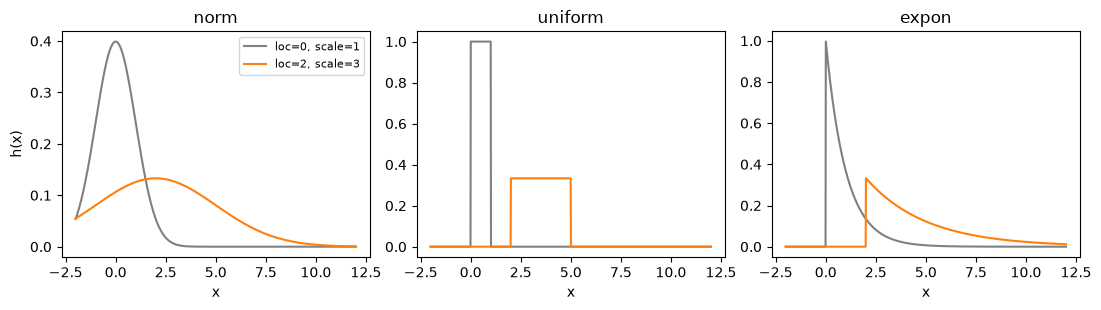

In [9]:
# Visualisation: the standardised distributions (grey) and the same with loc=2, scale=3 (colour)
x = np.linspace(-2, 12, 1000)
f, ax = plt.subplots(ncols=3, figsize=(11, 3.2), sharex=True)
for a, (name, dist) in zip(ax, [('norm', scipy.stats.norm), ('uniform', scipy.stats.uniform), ('expon', scipy.stats.expon)]):
    a.plot(x, dist.pdf(x), color='grey', label='loc=0, scale=1')
    a.plot(x, dist.pdf(x, loc=2, scale=3), color='C1', label='loc=2, scale=3')
    a.set_title(name)
    a.set_xlabel('x')
ax[0].set_ylabel('h(x)')
ax[0].legend(fontsize=8)
plt.tight_layout()

#### Density is not a probability

A very common mistake is to read the value of a pdf, $h(x_0)$, as "the probability of getting $x_0$". For a continuous random variable this is wrong:

- $p(X = x_0) = 0$ for any single value $x_0$. What is non-zero is the probability of an *interval*, which for a small width $\delta x$ is approximately $p(x_0 - \delta x/2 < X < x_0 + \delta x/2) \simeq h(x_0)\,\delta x$.
- $h(x)$ is a probability *per unit of $x$*: it has the unit of $1/[x]$ and **can be larger than 1**. Only the integral of $h$ is bounded by 1.
- For a **discrete** variable, the pmf values *are* probabilities and are between 0 and 1.
- A histogram with `density=True` shows densities (heights), not probabilities: the probability is height $\times$ bin width (the area of the bar).

**Exercise.** A sensor measures a small displacement $X$ (in metres) with a gaussian noise: $X \sim \mathcal{N}(0, \sigma^2)$ with $\sigma = 0.1$ m.

1. Compute the value of the pdf at $x = 0$. Is it a problem that it is larger than 1?
2. Compute $p(|X| < 1\,{\rm cm})$ from the CDF, and compare with the approximation $h(0) \times (\text{width of the interval})$.
3. Draw $10^5$ values from this distribution and plot the histogram with `density=True`. What is the height of the highest bar? Check that $\sum_i h_i\,\delta x_i = 1$, but that $\sum_i h_i \neq 1$.
4. Express the displacement in centimetres, $Y = 100\,X$. What is now the value of the pdf at 0? What happens to the probability $p(|Y| < 1\,{\rm cm})$?
5. Compare with a discrete variable: compute the sum and the maximum of the pmf of a Poisson distribution of mean 10.

In [ ]:
# Possible solution (instructor version; remove before handing out)
sigma = 
X = scipy.stats.norm(loc=, scale=)                     # X in metres

# 1) the pdf at 0
print('1) h(0) = %.3f  [1/m]   -> a density, it may exceed 1' % X.)

In [ ]:
# 2) probability of a small interval: exact (CDF) vs density x width
eps =                                                     # 1 cm
p_exact =   # using CDF 
p_approx =  # PDF x bin width 
print('2) p(|X| < 1 cm) = %.4f   (h(0) * width = %.4f)   and p(X = 0) = 0' % (p_exact, p_approx))

In [ ]:
# 3) density histogram of a sample
xs =   
heights, edges = np.histogram(xs, bins=50, density=True)
widths = np.diff(edges)   # calculate the bin widths with np.diff()
print('3) highest bar = %.2f ; sum(h*dx) = %.3f ; sum(h) = %.1f' % ())

In [ ]:
# 4) same variable in centimetres
Y = scipy.stats.norm(loc=0, scale=100 * sigma)                # Y = 100 X, in cm
print('4) h_Y(0) = %.4f  [1/cm]   but p(|Y| < 1 cm) = %.4f  (same probability)' % ()

In [ ]:
# 5) a pmf: values are probabilities
pois10 = scipy.stats.poisson(10)
k = np.arange(0, 100)
print('5) Poisson(10): sum of pmf = %.3f ; max of pmf = %.3f' % (pois10.pmf(k).sum(), pois10.pmf(k).max()))

1) h(0) = 3.989  [1/m]   -> a density, it may exceed 1
2) p(|X| < 1 cm) = 0.0797   (h(0) * width = 0.0798)   and p(X = 0) = 0
3) highest bar = 3.95 ; sum(h*dx) = 1.000 ; sum(h) = 58.1
4) h_Y(0) = 0.0399  [1/cm]   but p(|Y| < 1 cm) = 0.0797  (same probability)
5) Poisson(10): sum of pmf = 1.000 ; max of pmf = 0.125


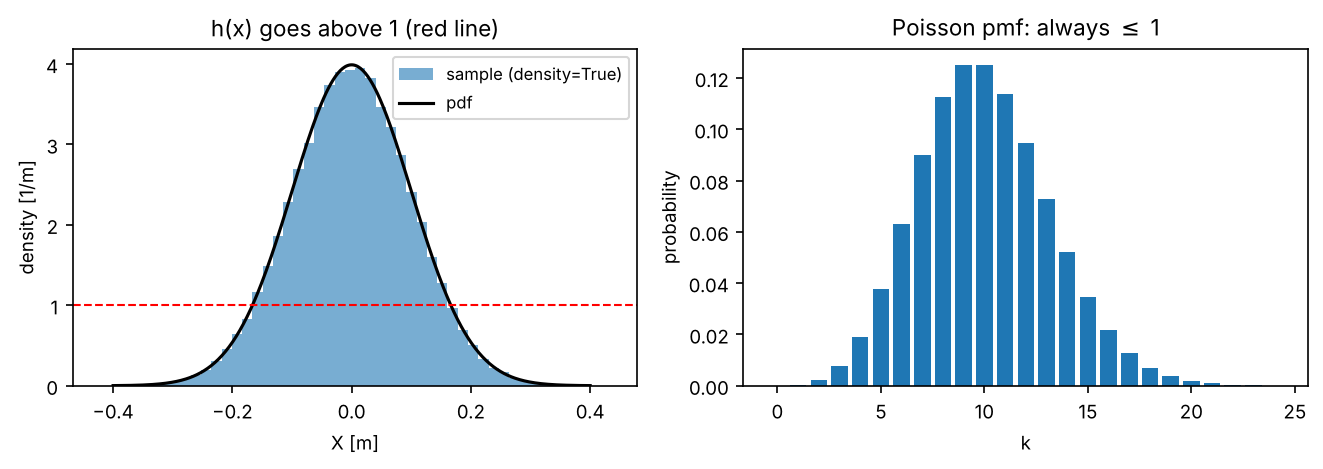

In [20]:
f, ax = plt.subplots(ncols=2, figsize=(9, 3.2))
xm = np.linspace(-0.4, 0.4, 400)
ax[0].hist(xs, bins=50, density=True, alpha=0.6, label='sample (density=True)')
ax[0].plot(xm, X.pdf(xm), 'k', label='pdf')
ax[0].axhline(1, color='r', ls='--', lw=1)
ax[0].set_xlabel('X [m]'); ax[0].set_ylabel('density [1/m]'); ax[0].legend(fontsize=8)
ax[0].set_title('h(x) goes above 1 (red line)')
ax[1].bar(k[:25], pois10.pmf(k[:25]))
ax[1].set_xlabel('k'); ax[1].set_ylabel('probability'); ax[1].set_title('Poisson pmf: always $\\leq$ 1')
plt.tight_layout()

### I.4a Common probability distributions

The concepts outlined above are part of the prerequisites for this course. A refresh of the characteristics of PDFs, and examples of common PDFs is provided in:

- [Descriptive_statistics_01.ipynb](Descriptive_statistics_01.ipynb): **properties of probability distribution functions** (mean, standard deviation, variance, skewness, ...).
- [Descriptive_statistics_02.ipynb](Descriptive_statistics_02.ipynb): an interactive tour of the characteristics and properties of **common distributions** encountered in science.

### I.4b Bivariate density function

One-dimensional distribution functions (discussed so far) describe the distribution of a single random variable $x$. One can similarly define a two-dimensional distribution of two *continuous random variables* $x, y$, i.e. $h(x, y)$ such that $\int_{-\infty}^{+\infty} {\rm d}x \int_{-\infty}^{+\infty} h(x, y) \, {\rm d}y = 1$. This distribution should be interpreted as giving the probability density that $x$ is between $x$ and $x + {\rm d}x$ *and* that $y$ is between $y$ and $y + {\rm d}y$ (remember the definition of the intersection between 2 events during the previous lecture). As in 1D, $h(x,y)$ is a *density* (probability per unit area $\,{\rm d}x\,{\rm d}y$), not a probability.

Such a distribution of 2 random variables is called a **bivariate distribution**.

In analogy to the 1D PDF, the variances on $x$ and $y$ are defined as:

$$
{\rm{Var}}(x) \, = \, \int_{-\infty}^{+\infty} \int_{-\infty}^{+\infty} (x-\langle x \rangle)^2\,h(x, y)\,{\rm d}x\, {\rm d}y
$$
$$
{\rm{Var}}(y) \, = \, \int_{-\infty}^{+\infty} \int_{-\infty}^{+\infty} (y-\langle y \rangle)^2\,h(x, y)\,{\rm d}x\, {\rm d}y
$$

where the mean values are defined as

$$
\langle x \rangle = \int_{-\infty}^{+\infty} \int_{-\infty}^{+\infty} x\,h(x, y)\,{\rm d}x\, {\rm d}y
$$
$$
\langle y \rangle = \int_{-\infty}^{+\infty} \int_{-\infty}^{+\infty} y\,h(x, y)\,{\rm d}x\, {\rm d}y
$$

Finally, one also defines the covariance of $x$ and $y$ as:

$$
{\rm{Cov}}(x, y) \, = \, \int_{-\infty}^{+\infty} \int_{-\infty}^{+\infty} (x \,-\, \langle x \rangle) \, (y \,-\, \langle y \rangle) \,h(x, y)\,{\rm d}x\, {\rm d}y
$$

This measures the *linear* dependence between the 2 variables $x$ and $y$. The covariance is equal to 0 when the 2 variables are uncorrelated. Beware that *uncorrelated* does not mean *independent*: independent variables always have zero covariance, but the reverse is true in general only for jointly gaussian variables (e.g. $y = x^2$ with $x$ symmetric around 0 has a strongly dependent $y$, but ${\rm Cov}(x, y) = 0$).

The *marginal distribution* $m(x)$ (resp. $m(y)$) is obtained by integrating $h(x, y)$ over all the values of $y$ (resp. $x$):

$$
m(x) = \int h(x,y) \, {\rm d}y
$$

The marginal distribution **should not be confused with**: 
- a *slice* $h(x, y=y_0)$ of the 2D density,
- nor with the *conditional distribution* $h(x\,|\,y_0) = h(x, y_0) / m(y_0)$, which is the slice renormalised so that its integral over $x$ equals 1 (the division by $m(y_0)$ is the 2D version of $p(A|B) = p(A \cap B)/p(B)$).

The marginal $m(x)$ and the conditional $h(x\,|\,y_0)$ are both properly normalised pdfs, the slice is not. For correlated variables the conditional distribution is in general different from (for a gaussian: narrower than) the marginal. We will see the difference on the example below.

#### Example: bivariate normal distribution

Use of `scipy.stats.multivariate_normal()` for a multivariate **gaussian** distribution.

The expression of the bivariate gaussian distribution is:

$$
h(x, y \,|\, \mu_x, \mu_y, \sigma_x, \sigma_y, \sigma_{xy}) = \frac{1}{2 \, \pi \, \sigma_x \sigma_y \sqrt{1 - \rho^2}} \, \exp\left(\frac{-z^2}{2(1-\rho^2)}\right)
$$

where
$$
z^2 = \frac{(x-\mu_x)^2}{\sigma^2_x} + \frac{(y-\mu_y)^2}{\sigma^2_y} - 2 \, \rho \, \frac{(x-\mu_x)\,(y-\mu_y)}{\sigma_x\,\sigma_y}
$$

and the dimensionless correlation coefficient between $x$ and $y$ is:
$$
\rho = \frac{\sigma_{xy}}{\sigma_x\,\sigma_y} = \frac{{\rm Cov}(x,y)}{\sqrt{{\rm Var}(x)\,{\rm Var}(y)}}
$$

The contours of the bivariate distribution are ellipses inclined by an angle $\alpha$ (defined for $-\pi/2 < \alpha < \pi/2$) between the $x$-axis and the major axis of the ellipse. Its value is given by:
$$
\tan({2\,\alpha}) = 2\,\rho \frac{\sigma_x \sigma_y}{\sigma_x^2 - \sigma_y^2} = 2\,\frac{\sigma_{xy}}{\sigma_x^2 - \sigma_y^2}
$$

One can show (see [below](#i.4c-multivariate-normal-distribution)) that the variance of the marginal distribution $m(x)$ is $\sigma_{x}^2 \equiv {\rm{Var}}(x)$, and similarly the variance of $m(y)$ is $\sigma_{y}^2 \equiv {\rm{Var}}(y)$.

rho = sigma_xy / (sigma_x * sigma_y) = 0.30


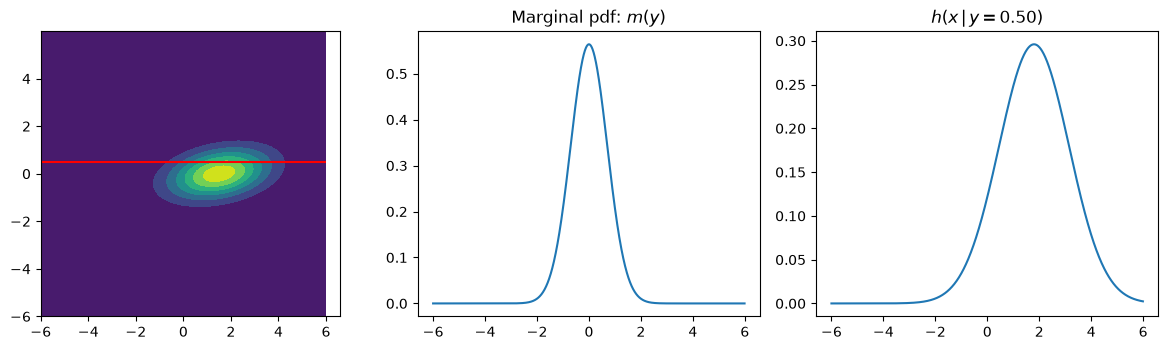

In [12]:
step = 0.01
x, y = np.arange(-6., 6., step), np.arange(-6, 6., step)
X, Y = np.meshgrid(x, y)
# X, Y = np.mgrid[-6:6:.01, -6:6:.01]    # Alternative command to generate a meshgrid!
# I now create a 3D array containing the X and Y coordinates
pos = np.zeros(X.shape + (2,))
pos[:, :, 0] = X
pos[:, :, 1] = Y

# Non isotropic bivariate normal distribution
# Warning: we give elements of the covariance matrix (variances on the diagonal, NOT standard deviations)!
cov_mtx = np.array([[2.0, 0.3], [0.3, 0.5]])
#cov_mtx = np.array([[0.5, 0.3], [0.3, 2.0]])
rho = cov_mtx[0, 1] / np.sqrt(cov_mtx[0, 0] * cov_mtx[1, 1])    # sigma_xy / (sigma_x * sigma_y)

# rho = 0
#cov_mtx = np.array([[2.0, 0.0], [0.0, 0.5]])
#rho = cov_mtx[0, 1] / np.sqrt(cov_mtx[0, 0] * cov_mtx[1, 1])

print('rho = sigma_xy / (sigma_x * sigma_y) = %.2f' % rho)
n_2d = scipy.stats.multivariate_normal(mean=np.array([1.5, 0.]), cov=cov_mtx)
f, ax = plt.subplots(figsize=(12, 3.6), ncols=3)
ax[0].contourf(X, Y, n_2d.pdf(pos))
ax[0].set_aspect('equal')  # same unit length along x and y

# Calculates the marginal pdf
ax[1].plot(y, n_2d.pdf(pos).sum(axis=1) * step)   # sum over the x axis (axis=1), times dx
ax[1].set_title('Marginal pdf: $m(y)$')

# Plot h(x | y=yval) where yval = 0.5
yid = 650   # y = 0.5
ax[0].hlines(y[yid], -6, 6, color='red')
ax[2].plot(x, n_2d.pdf(pos)[yid, :] / (n_2d.pdf(pos).sum(axis=1)[yid] * step))   # renormalisation by m(y) at y=yid
ax[2].set_title('$h(x\\,|\\,y =%.2f )$' % y[yid])
plt.tight_layout()

# Plot h(y, x=xval) where xval = 1 
# define xid: index of xarray for which I want to know the conditional pdf h(y, x=xid)
#xid = 800
#ax[0].vlines(x[xid]-step/2., -6, 6, color='red')
#ax[2].plot(y, n_2d.pdf(pos)[:, xid]   / (n_2d.pdf(pos).sum(axis=0)[xid] * step)) # Note the renormalisation by p(x) at x=xid
#ax[2].set_title('$h(y, x =%.2f )$'%x[xid])


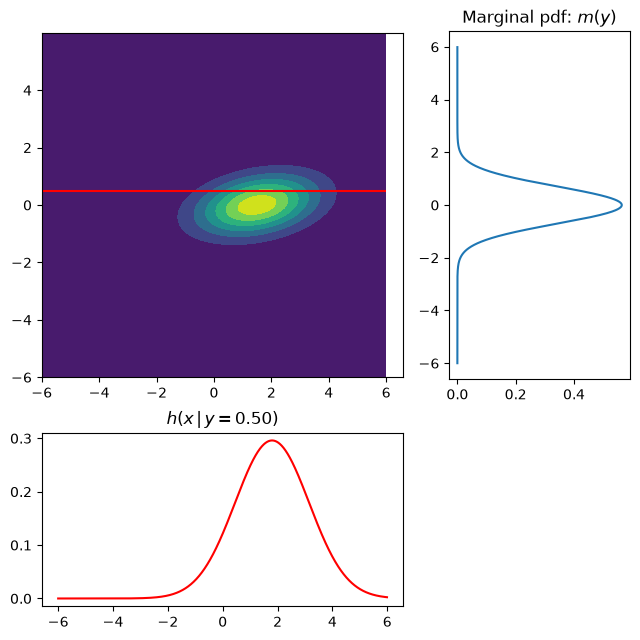

In [13]:
# A nicer visualisation
fig = plt.figure(figsize=(6.5, 6.5))
ax = gridspec.GridSpec(
    2, 2, width_ratios=[2, 1], height_ratios=[2, 1])

ax0 = plt.subplot(ax[0])
col_ax0 = ax0.contourf(X, Y, n_2d.pdf(pos))
ax0.set_aspect('equal')  # same unit length along x and y
ax0.hlines(y[yid], -6, 6, color='red')

# plot the marginal pdf
ax1 = plt.subplot(ax[1])
ax1.plot(n_2d.pdf(pos).sum(axis=1) * step, y)   # sum over the x axis ; x and y inverted for plotting
ax1.set_title('Marginal pdf: $m(y)$')

# Plot h(x | y=yval) where yval = 0.5
yid = 650   # y = 0.5
ax2 = plt.subplot(ax[2])
ax2.plot(x, n_2d.pdf(pos)[yid, :] / (n_2d.pdf(pos).sum(axis=1)[yid] * step), color='red')   # renormalisation by m(y) at y=yid
ax2.set_title('$h(x\\,|\\,y =%.2f )$' % y[yid])
plt.tight_layout()



### I.4c Multivariate normal distribution

[**This is supplementary material**] In fact, one can generalise the bivariate normal distribution (or gaussian distribution: we use both names) to $d$ dimensions. A multivariate normal distribution represents the distribution of a multivariate random variable that is made up of multiple random variables that can be correlated with each other. This multivariate normal distribution is best written using matrix formalism. It is characterised by the mean vector $\symbf{\mu}$, which is the expected value of the distribution, and the covariance matrix $\Sigma$, which measures how the random variables change together.

The multivariate normal with dimensionality $d$ has a joint probability density given by:

$$
h(\mathbf{x} \mid \symbf{\mu}, \Sigma) = \frac{1}{\sqrt{(2\pi)^d \lvert\Sigma\rvert}} \exp{ \left( -\frac{1}{2}(\mathbf{x} - \symbf{\mu})^T \Sigma^{-1} (\mathbf{x} - \symbf{\mu}) \right)}
$$

where $\mathbf{x}$ is a random vector of size $d$, $\symbf{\mu}$ is the mean vector, $\Sigma$ is the symmetric and positive definite covariance matrix (of size $d \times d$; its diagonal elements are the *variances*, $\Sigma_{ii} = \sigma_i^2$), and $\lvert\Sigma\rvert$ its determinant. We denote this multivariate normal distribution as:

$$
\mathcal{N}(\symbf{\mu}, \Sigma)
$$

If the distribution is a multivariate gaussian, the marginal and conditional distributions are also gaussian.

If we split the vector into two blocks, we have:
$$
\begin{bmatrix}
\mathbf{x_1} \\
\mathbf{x_2}
\end{bmatrix}
\sim
\mathcal{N}\left(
\begin{bmatrix}
\symbf{\mu}_{1} \\
\symbf{\mu}_{2}
\end{bmatrix},
\begin{bmatrix}
\Sigma_{11} & \Sigma_{12} \\
\Sigma_{21} & \Sigma_{22}
\end{bmatrix}
\right)
= \mathcal{N}(\symbf{\mu}, \Sigma)
, \qquad \Sigma_{21} = \Sigma_{12}^T
$$

The marginal distributions of each block $\mathbf{x_1}$ and $\mathbf{x_2}$ (for our bivariate example, $\mathbf{x_1} = x$ and $\mathbf{x_2} = y$) are: 

$$
\begin{aligned}
m(\mathbf{x_1}) & = \mathcal{N}(\symbf{\mu}_{1}, \Sigma_{11}) \\
m(\mathbf{x_2}) & = \mathcal{N}(\symbf{\mu}_{2}, \Sigma_{22})
\end{aligned}
$$

In [14]:
# We can check this out using the same example as above, using linear algebra capabilities of numpy
d = 2  # dimensions
mean = np.array([1.5, 0.])       # mean vector (mu_x, mu_y)
cov = np.array([
    [2.0, 0.3],
    [0.3, 0.5]
])

# Get the mean values from the vector
mean_x1 = mean[0]
mean_x2 = mean[1]
# Get the blocks (single values in this case) from the covariance matrix
sigma_11 = cov[0, 0]
sigma_22 = cov[1, 1]
sigma_12 = cov[0, 1]  # = sigma_21 in this case

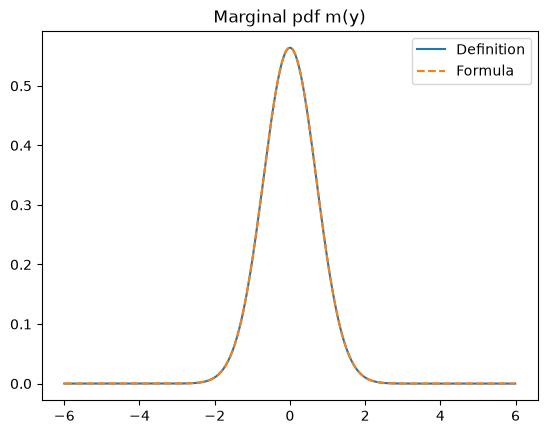

In [15]:
# marginal pdf m(y) - here y is equivalent to x2
# Numerical estimate
plt.plot(y, n_2d.pdf(pos).sum(axis=1) * step, label='Definition')

# "theory" pdf
# /!\ Beware: scipy.stats.norm(mean, std) takes the standard deviation,
# whereas scipy.stats.multivariate_normal(mean, cov) takes the covariance (the variance in 1D)
#py_marginal_1d = scipy.stats.norm(mean_x2, np.sqrt(sigma_22))
# plt.plot(y, py_marginal_1d.pdf(y))

py_marginal = scipy.stats.multivariate_normal(mean_x2, sigma_22)
plt.plot(y, py_marginal.pdf(y), '--', label='Formula')
plt.title("Marginal pdf m(y)")
plt.legend()

The **conditional distribution** of $\mathbf{x_1}$ given $\mathbf{x_2}$ is defined as:

$$
h(\mathbf{x_1} \mid \mathbf{x_2}) = \mathcal{N}(\symbf{\mu}_{1|2}, \Sigma_{1|2})
$$

With mean:

$$
\symbf{\mu}_{1|2} = \symbf{\mu}_{1} + \Sigma_{12} \Sigma_{22}^{-1} \left(\mathbf{x_2} -\symbf{\mu}_{2}\right)
$$

and covariance matrix

$$
\Sigma_{1|2} = \Sigma_{11}-\Sigma_{12}\Sigma_{22}^{-1}\Sigma_{21}
$$

with $\Sigma_{11}-\Sigma_{12}\Sigma_{22}^{-1}\Sigma_{21}$ being the [Schur complement](https://en.wikipedia.org/wiki/Schur_complement) of $\Sigma_{22}$ (note that in that expression, we have made use of $\Sigma^T_{12} = \Sigma_{21}$). Note that the conditional covariance does not depend on the value of $\mathbf{x_2}$, and is smaller than $\Sigma_{11}$ when the variables are correlated: knowing $y$ reduces the uncertainty on $x$.

conditional mean = 1.800, conditional variance = 1.820 (marginal variance of x: 2.000)


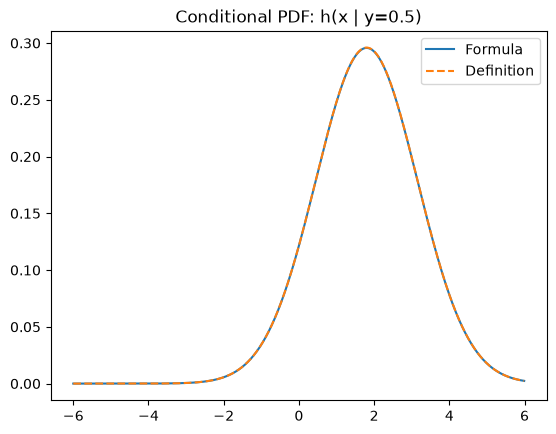

In [16]:
# Calculate h(x | y=0.5)
# Calculation through proper algebra
y_condition = 0.5  # To condition on y = 0.5
mean_xgiveny = mean_x1 + (sigma_12 * (1/sigma_22) * (y_condition - mean_x2))
cov_xgiveny = sigma_11 - sigma_12 * (1/sigma_22) * sigma_12

# Numerical estimate
px_giveny = scipy.stats.multivariate_normal(mean_xgiveny, cov_xgiveny)
plt.plot(x, px_giveny.pdf(x), label='Formula')  # y=0.5

plt.plot(x, n_2d.pdf(pos)[yid, :] / (n_2d.pdf(pos).sum(axis=1)[yid] * step), '--', label='Definition')   # renormalisation by m(y) at y=yid
plt.title("Conditional PDF: h(x | y=0.5)")
plt.legend()
print('conditional mean = %.3f, conditional variance = %.3f (marginal variance of x: %.3f)' % (mean_xgiveny, cov_xgiveny, sigma_11))

#### Supplementary exercise

- Check that the conditional and marginal distributions are effectively pdfs, namely that their integral equals 1.
- Calculate $h(y\,|\,x=1.0)$.

## Summary

We have reviewed basic statistical concepts and quantities, and how to use them in python. In particular:

- basic probability concepts: a sample space, a realisation, an event, a conditional probability (i.e. $p(A|B)$ is the probability of $A$ given $B$).
- what is a **random variable** (this is a key concept!), and how to generate and manipulate random variables with numpy using a generator `rng = np.random.default_rng(seed)`: `rng.random()`, `rng.integers()`, `rng.choice()`, `rng.permutation()`. The seed makes the results reproducible; the legacy `np.random.seed(value)` / `np.random.randint()` interface is equivalent in spirit but acts on a hidden global state.
- Probability density function (pdf) and cumulative distribution function (CDF) (you *need* to understand what these functions are very well!). A density is not a probability: only its integral over an interval is.
- How to manipulate distributions with `scipy.stats`. For example, to work with a gaussian, and subsequently calculate pdf, cdf, ... or draw samples: `g = scipy.stats.norm()` followed by `g.pdf(x)` to get a pdf evaluated at values `x` (single value or array), `g.cdf(x)` for the cdf, `g.rvs(size, random_state=rng)` for a random sample. `loc` and `scale` shift and stretch the standardised distribution; they are the mean and std only for the gaussian.
- Bivariate pdf, marginal and conditional distributions, and multivariate distributions.
- The expression of a multivariate normal distribution: beware of the definition of the univariate and multivariate normal distributions in scipy: use of the std in `scipy.stats.norm(mu, sig)` but of the covariance in `scipy.stats.multivariate_normal(mu, cov)`.

## X. References and supplementary material

* **Chapter 1** (1.2), **Chapter 3** (3.1, 3.2, 3.5) and **Chapter 4** (4.1 to 4.3) of the book *Statistics, data mining and Machine learning in astronomy* by Z. Ivezic et al., Princeton Series in Modern Astronomy.
* Youtube video about Random variable and PDF: https://www.youtube.com/watch?v=9KVR1hJ8SxI : first 7 minutes
* Youtube video about CDF and its link to PDF: https://www.youtube.com/watch?v=4BswLMKgXzU : first 6 minutes
* *All of statistics: a concise course in statistical inference*, Wasserman 2004 (see also errata in http://www.stat.cmu.edu/~larry/all-of-statistics/) and personal notes from "Telmo Correa" here https://github.com/telmo-correa/all-of-statistics/tree/master.
* *Statistics in theory and Practice*, Lupton 1993: **Chapter 2**
* [Numerical recipes](http://www2.units.it/ipl/students_area/imm2/files/Numerical_Recipes.pdf) by Press et al., Cambridge University Press: **Chapter 15**, **Chapter 18.7**
* Numpy documentation on random generators: [https://numpy.org/doc/stable/reference/random/index.html](https://numpy.org/doc/stable/reference/random/index.html)